# EMQA_data

**The data of the course: sources, coverage and loading**

Energy Markets Quantitative Analysis (EMQA) · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/Data/EMQA_data/EMQA_data.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

## The download scripts

`download_all.py` downloads every series from its public source, keeps the raw answers in `data/raw/` and writes the clean files in `data/clean/`; `download_L5.py` and `download_L6.py` add the series of Lectures 5 and 6. Nothing is interpolated: gaps stay gaps. Intraday power timestamps are in UTC (Coordinated Universal Time, start of the interval); daily power averages use the Central European calendar day (CET/CEST); market data use exchange trading dates. The Romanian equities need a free EODHD key in a `.env` file (`EODHD_API_KEY=...`).

Set `RUN_DOWNLOAD = True` to download everything again (about 15 minutes); by default the notebook reads the files already published with the course.

In [2]:
RUN_DOWNLOAD = False
if RUN_DOWNLOAD:
    import subprocess, sys
    for s in ('download_all.py', 'download_L5.py', 'download_L6.py'):
        subprocess.run([sys.executable, s], check=True)   # copies of data/*.py, in this folder

## The files of `data/clean` and the period each one covers

In [3]:
import pandas as pd
FILES = {  # file: (time column, what it holds)
    'power_da_prices_hourly_utc.csv': ('timestamp_utc', 'Day-ahead prices RO, BG, HU, DE-LU (EUR/MWh), hourly'),
    'power_da_prices_native_utc.csv': ('timestamp_utc', 'Day-ahead prices at native resolution (15 min from Oct 2025)'),
    'power_da_prices_daily_cet.csv': ('date_cet', 'Day-ahead prices, daily averages (CET day)'),
    'generation_ro_mw_hourly_utc.csv': ('timestamp_utc', 'Romania: generation by source and load (MW), hourly'),
    'generation_bg_mw_hourly_utc.csv': ('timestamp_utc', 'Bulgaria: generation by source and load (MW), hourly'),
    'generation_hu_mw_native_utc.csv': ('timestamp_utc', 'Hungary: wind, solar and load (MW)'),
    'crossborder_ro_mw_hourly_utc.csv': ('timestamp_utc', 'Romania: cross-border physical flows (MW, + = import)'),
    'fuels_daily.csv': ('date', 'Brent, WTI, Henry Hub, gasoline, heating oil; EUR/USD'),
    'ttf_monthly.csv': ('month', 'TTF natural gas, monthly'),
    'eua_daily.csv': ('date', 'EU carbon allowances (EUA), EUR/t'),
    'ecb_ron_estr_daily.csv': ('date', 'EUR/RON and euro short-term rate'),
    'ro_energy_equities_daily.csv': ('date', 'Hidroelectrica, Nuclearelectrica, OMV Petrom, Romgaz (RON)'),
    'opcom_forward_trades.csv': ('auction_date', 'OPCOM forward market trades'),
}
rows = []
for f, (col, what) in FILES.items():
    t = pd.read_csv(DATA + f, usecols=[col])[col]
    t = pd.to_datetime(t, utc=True, errors='coerce', format='mixed')
    rows.append({'file': f, 'content': what, 'first': t.min().date(), 'last': t.max().date(), 'rows': len(t)})
COV = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 80)
COV

,file,content,first,last,rows
0,power_da_prices_hourly_utc.csv,"Day-ahead prices RO, BG, HU, DE-LU (EUR/MWh), hourly",2015-01-01,2026-11-05,103847
1,power_da_prices_native_utc.csv,Day-ahead prices at native resolution (15 min from Oct 2025),2015-01-01,2026-11-05,132722
2,power_da_prices_daily_cet.csv,"Day-ahead prices, daily averages (CET day)",2015-01-01,2026-11-05,4327
3,generation_ro_mw_hourly_utc.csv,"Romania: generation by source and load (MW), hourly",2015-01-01,2026-11-04,103818
4,generation_bg_mw_hourly_utc.csv,"Bulgaria: generation by source and load (MW), hourly",2015-01-01,2026-11-04,103809
5,generation_hu_mw_native_utc.csv,"Hungary: wind, solar and load (MW)",2018-12-30,2026-11-05,275236
6,crossborder_ro_mw_hourly_utc.csv,"Romania: cross-border physical flows (MW, + = import)",2015-01-01,2026-11-04,103824
7,fuels_daily.csv,"Brent, WTI, Henry Hub, gasoline, heating oil; EUR/USD",2015-01-02,2026-11-04,3059
8,ttf_monthly.csv,"TTF natural gas, monthly",2015-01-01,2026-10-01,142
9,eua_daily.csv,"EU carbon allowances (EUA), EUR/t",2015-01-08,2026-11-04,2682


## Chart: period covered by each file

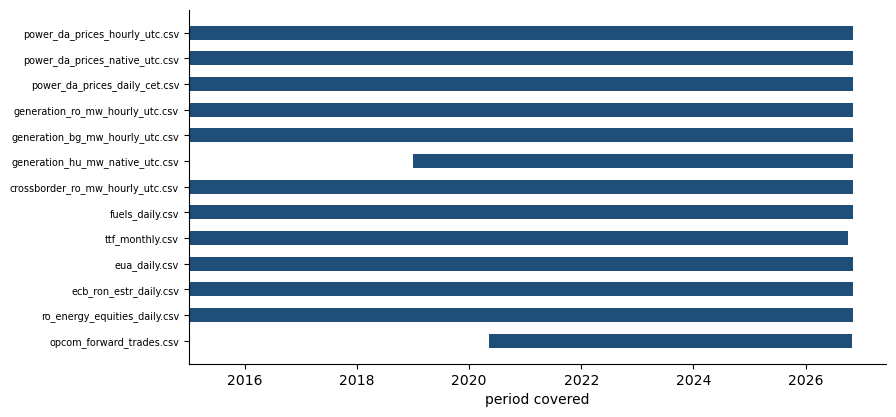

In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False})
fig, ax = plt.subplots(figsize=(9, 4.6))
for i, r in COV.iloc[::-1].reset_index(drop=True).iterrows():
    ax.barh(i, (pd.Timestamp(r['last']) - pd.Timestamp(r['first'])).days, left=pd.Timestamp(r['first']), height=0.55, color='#1F4E79')
ax.set_yticks(range(len(COV))); ax.set_yticklabels(COV['file'].iloc[::-1], fontsize=7)
ax.set_xlabel('period covered')
fig.patch.set_alpha(0); ax.patch.set_alpha(0)
plt.savefig('data_coverage.png', dpi=150, bbox_inches='tight', transparent=True); plt.show()

## Loading a series

Example: hourly day-ahead prices of Romania and Bulgaria, in local time.

In [5]:
p = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', index_col=0, parse_dates=True)
p.index = pd.to_datetime(p.index, utc=True).tz_convert('Europe/Bucharest')
p[['RO', 'BG']].tail()

,RO,BG
timestamp_utc,,
2026-11-05 20:00:00+02:00,378.4475,378.0025
2026-11-05 21:00:00+02:00,378.9625,378.2375
2026-11-05 22:00:00+02:00,374.2300,373.6700
2026-11-05 23:00:00+02:00,341.0400,340.5225
2026-11-06 00:00:00+02:00,NaN,NaN
